In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
file_path = r"C:\Users\Pritish Kumar\Downloads\ASUSE_DATA_2023_24_CSV\ASUSE_DATA_2023_24_CSV\LEVEL - 02(Block 2) (1).csv"

df = pd.read_csv(
    file_path,
    dtype=str,
    low_memory=False
)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully!
Rows: 523775
Columns: 57


In [4]:
df.head()

,fsu_serial_no,schedule,sector,nss_region,district,stratum,sub_stratum,sub_round,fod_sub_region,segment_no,...,reg_additional2,reg_additional3,manuf_services,contract_manuf_service,contract_type,equipment_by_contractor,other_contract_services,other_contract_type,franchise,mlt
0,46663,ESU,1,012,05,012,03,4,0110,1,...,98,NaN,2,NaN,NaN,NaN,2,NaN,2,2342.86
1,46663,ESU,1,012,05,012,03,4,0110,1,...,NaN,NaN,2,NaN,NaN,NaN,2,NaN,2,2342.86
2,46663,ESU,1,012,05,012,03,4,0110,1,...,98,NaN,2,NaN,NaN,NaN,2,NaN,2,2342.86
3,46663,ESU,1,012,05,012,03,4,0110,1,...,98,NaN,2,NaN,NaN,NaN,2,NaN,2,2342.86
4,46663,ESU,1,012,05,012,03,4,0110,1,...,NaN,NaN,2,NaN,NaN,NaN,2,NaN,2,2342.86


In [5]:
df.shape

(523775, 57)

In [6]:
pd.DataFrame({
    "Column Number": range(1, len(df.columns) + 1),
    "Column Name": df.columns
})

,Column Number,Column Name
0,1,fsu_serial_no
1,2,schedule
2,3,sector
3,4,nss_region
4,5,district
5,6,stratum
6,7,sub_stratum
7,8,sub_round
8,9,fod_sub_region
9,10,segment_no


In [7]:
print("Dataset Shape:")
display(df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
display(df.info())

Dataset Shape:


(523775, 57)


First 5 Rows:


,fsu_serial_no,schedule,sector,nss_region,district,stratum,sub_stratum,sub_round,fod_sub_region,segment_no,...,reg_additional2,reg_additional3,manuf_services,contract_manuf_service,contract_type,equipment_by_contractor,other_contract_services,other_contract_type,franchise,mlt
0,46663,ESU,1,012,05,012,03,4,0110,1,...,98,NaN,2,NaN,NaN,NaN,2,NaN,2,2342.86
1,46663,ESU,1,012,05,012,03,4,0110,1,...,NaN,NaN,2,NaN,NaN,NaN,2,NaN,2,2342.86
2,46663,ESU,1,012,05,012,03,4,0110,1,...,98,NaN,2,NaN,NaN,NaN,2,NaN,2,2342.86
3,46663,ESU,1,012,05,012,03,4,0110,1,...,98,NaN,2,NaN,NaN,NaN,2,NaN,2,2342.86
4,46663,ESU,1,012,05,012,03,4,0110,1,...,NaN,NaN,2,NaN,NaN,NaN,2,NaN,2,2342.86



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 523775 entries, 0 to 523774
Data columns (total 57 columns):
 #   Column                   Non-Null Count   Dtype
---  ------                   --------------   -----
 0   fsu_serial_no            523775 non-null  str  
 1   schedule                 523775 non-null  str  
 2   sector                   523775 non-null  str  
 3   nss_region               523775 non-null  str  
 4   district                 523775 non-null  str  
 5   stratum                  523775 non-null  str  
 6   sub_stratum              523775 non-null  str  
 7   sub_round                523775 non-null  str  
 8   fod_sub_region           523775 non-null  str  
 9   segment_no               523775 non-null  str  
 10  second_stage_stratum_no  523775 non-null  str  
 11  sample_est_no            523775 non-null  str  
 12  level                    523775 non-null  str  
 13  mixed_activity           523775 non-null  str  
 14  major_nic_2dig           

None

In [8]:
# Basic information about the dataset

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
display(pd.DataFrame(df.columns, columns=["Column Name"]))

print("\nFirst 10 rows:")
display(df.head(10))

Number of rows: 523775
Number of columns: 57

Column names:


,Column Name
0,fsu_serial_no
1,schedule
2,sector
3,nss_region
4,district
5,stratum
6,sub_stratum
7,sub_round
8,fod_sub_region
9,segment_no



First 10 rows:


,fsu_serial_no,schedule,sector,nss_region,district,stratum,sub_stratum,sub_round,fod_sub_region,segment_no,...,reg_additional2,reg_additional3,manuf_services,contract_manuf_service,contract_type,equipment_by_contractor,other_contract_services,other_contract_type,franchise,mlt
0,46663,ESU,1,012,05,012,03,4,0110,1,...,98,NaN,2,NaN,NaN,NaN,2,NaN,2,2342.86
1,46663,ESU,1,012,05,012,03,4,0110,1,...,NaN,NaN,2,NaN,NaN,NaN,2,NaN,2,2342.86
2,46663,ESU,1,012,05,012,03,4,0110,1,...,98,NaN,2,NaN,NaN,NaN,2,NaN,2,2342.86
3,46663,ESU,1,012,05,012,03,4,0110,1,...,98,NaN,2,NaN,NaN,NaN,2,NaN,2,2342.86
4,46663,ESU,1,012,05,012,03,4,0110,1,...,NaN,NaN,2,NaN,NaN,NaN,2,NaN,2,2342.86
5,46663,ESU,1,012,05,012,03,4,0110,1,...,98,NaN,2,NaN,NaN,NaN,2,NaN,2,2733.33
6,46663,ESU,1,012,05,012,03,4,0110,1,...,98,NaN,1,2,NaN,NaN,2,NaN,2,2733.33
7,46663,ESU,1,012,05,012,03,4,0110,1,...,NaN,NaN,1,2,NaN,NaN,2,NaN,2,2733.33
8,46663,ESU,1,012,05,012,03,4,0110,1,...,NaN,NaN,1,2,NaN,NaN,2,NaN,2,2733.33
9,46663,ESU,1,012,05,012,03,4,0110,1,...,NaN,NaN,2,NaN,NaN,NaN,2,NaN,2,2733.33


In [9]:
# Missing value analysis

missing_df = pd.DataFrame({
    "Column": df.columns,
    "Missing Values": df.isna().sum().values,
    "Missing %": (df.isna().sum().values / len(df) * 100).round(2)
})

display(
    missing_df.sort_values(
        by="Missing Values",
        ascending=False
    )
)

,Column,Missing Values,Missing %
54,other_contract_type,522885,99.83
24,npish,520985,99.47
52,equipment_by_contractor,507409,96.88
51,contract_type,507409,96.88
16,minor_nic_2dig,503670,96.16
17,minor_nic_5dig,503670,96.16
48,reg_additional3,473688,90.44
38,next_severe_problem,462199,88.24
50,contract_manuf_service,411662,78.60
37,most_severe_problem,400713,76.50


In [10]:
# ============================================================
# STEP 9 - CREATE SCHEMEMATCH DATASET
# ============================================================

# Select features from the already-loaded dataset
selected_columns = [
    "mixed_activity",
    "major_nic_2dig",
    "ownership_type",
    "education_level",
    "technical_training",
    "social_group",
    "num_eco_activities",
    "bank_account",
    "location",
    "est_type",
    "years_of_operation",
    "nature_of_operation",
    "months_operated",
    "daily_work_hours",
    "accounts_maintained",
    "used_computer",
    "used_internet",
    "problems_faced",
    "registered",
    "franchise"
]

# Check columns
missing_columns = [col for col in selected_columns if col not in df.columns]

if len(missing_columns) > 0:
    print("❌ Missing columns:")
    print(missing_columns)
else:
    # Create SchemeMatch dataset
    scheme_df = df[selected_columns].copy()

    # Rename columns
    scheme_df.columns = [
        "mixed_activity",
        "major_activity_nic",
        "ownership_type",
        "education_level",
        "technical_training",
        "social_group",
        "economic_activities",
        "bank_account",
        "establishment_location",
        "establishment_type",
        "years_of_operation",
        "nature_of_operation",
        "months_operated",
        "working_hours",
        "accounts_maintained",
        "computer_used",
        "internet_used",
        "operational_problem",
        "registered",
        "franchise"
    ]

    # Convert numerical features
    numeric_features = [
        "economic_activities",
        "years_of_operation",
        "months_operated",
        "working_hours"
    ]

    for col in numeric_features:
        scheme_df[col] = pd.to_numeric(
            scheme_df[col],
            errors="coerce"
        )

    # Final output
    print("✅ SchemeMatch dataset created successfully!")
    print("Rows   :", f"{scheme_df.shape[0]:,}")
    print("Columns:", scheme_df.shape[1])

    print("\nFirst 10 records:")
    display(scheme_df.head(10))

✅ SchemeMatch dataset created successfully!
Rows   : 523,775
Columns: 20

First 10 records:


,mixed_activity,major_activity_nic,ownership_type,education_level,technical_training,social_group,economic_activities,bank_account,establishment_location,establishment_type,years_of_operation,nature_of_operation,months_operated,working_hours,accounts_maintained,computer_used,internet_used,operational_problem,registered,franchise
0,2,10,1,4,2,1,0.0,1,2,1,3,1,12,10,2,2,2,2,1,2
1,2,31,1,4,2,1,1.0,1,2,1,2,1,12,8,2,2,2,2,2,2
2,2,25,1,5,2,1,0.0,1,2,1,2,1,12,9,2,2,2,1,1,2
3,2,47,1,4,2,1,1.0,1,2,1,3,1,12,9,2,2,2,2,1,2
4,2,96,1,4,2,1,0.0,1,2,1,3,1,12,8,2,2,2,2,2,2
5,2,10,1,3,2,1,1.0,1,2,2,3,1,12,8,2,2,2,2,1,2
6,2,10,1,4,2,1,1.0,1,2,2,3,1,12,8,2,2,2,2,1,2
7,2,45,1,5,2,1,1.0,1,2,2,2,1,12,8,2,2,2,2,2,2
8,2,14,1,4,2,1,1.0,1,2,2,3,1,12,9,2,2,2,2,2,2
9,2,31,1,3,2,1,1.0,1,2,2,3,1,12,8,2,2,2,2,2,2


In [11]:
# ============================================================
# STEP 10 - CHECK MISSING VALUES
# ============================================================

missing_values = scheme_df.isna().sum()

missing_report = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (
        missing_values / len(scheme_df) * 100
    ).round(2)
})

display(
    missing_report.sort_values(
        by="Missing Values",
        ascending=False
    )
)

,Missing Values,Missing Percentage
education_level,26274,5.02
economic_activities,26274,5.02
social_group,26274,5.02
technical_training,26274,5.02
ownership_type,0,0.00
major_activity_nic,0,0.00
mixed_activity,0,0.00
bank_account,0,0.00
establishment_location,0,0.00
establishment_type,0,0.00


In [12]:
# ============================================================
# STEP 11 - HANDLE MISSING VALUES
# ============================================================

# Numerical features
numeric_features = [
    "economic_activities",
    "years_of_operation",
    "months_operated",
    "working_hours"
]

# Categorical features
categorical_features = [
    "mixed_activity",
    "major_activity_nic",
    "ownership_type",
    "education_level",
    "technical_training",
    "social_group",
    "bank_account",
    "establishment_location",
    "establishment_type",
    "nature_of_operation",
    "accounts_maintained",
    "computer_used",
    "internet_used",
    "operational_problem",
    "registered",
    "franchise"
]

# Fill numerical missing values with median
for col in numeric_features:
    scheme_df[col] = scheme_df[col].fillna(
        scheme_df[col].median()
    )

# Keep categorical missing values as a separate category
for col in categorical_features:
    scheme_df[col] = scheme_df[col].fillna("Missing")

print("✅ Missing values handled successfully!")

# Verify
print("\nRemaining missing values:")

display(
    scheme_df.isna().sum().to_frame("Missing Values")
)

✅ Missing values handled successfully!

Remaining missing values:


,Missing Values
mixed_activity,0
major_activity_nic,0
ownership_type,0
education_level,0
technical_training,0
social_group,0
economic_activities,0
bank_account,0
establishment_location,0
establishment_type,0


In [13]:
# ============================================================
# STEP 12 - PREPROCESS DATA FOR K-MEANS
# ============================================================

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

# Numerical features
numeric_features = [
    "economic_activities",
    "years_of_operation",
    "months_operated",
    "working_hours"
]

# Categorical features
categorical_features = [
    "mixed_activity",
    "major_activity_nic",
    "ownership_type",
    "education_level",
    "technical_training",
    "social_group",
    "bank_account",
    "establishment_location",
    "establishment_type",
    "nature_of_operation",
    "accounts_maintained",
    "computer_used",
    "internet_used",
    "operational_problem",
    "registered",
    "franchise"
]

# Create preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("numerical", StandardScaler(), numeric_features),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            ),
            categorical_features
        )
    ]
)

# Apply preprocessing
X = preprocessor.fit_transform(scheme_df)

print("✅ Preprocessing completed successfully!")
print("=" * 50)
print(f"Original features  : {scheme_df.shape[1]}")
print(f"Processed features : {X.shape[1]}")
print(f"Rows               : {X.shape[0]:,}")
print(f"Matrix shape       : {X.shape}")

✅ Preprocessing completed successfully!
Original features  : 20
Processed features : 129
Rows               : 523,775
Matrix shape       : (523775, 129)


Sample used for K selection: 10,000 rows
Testing K = 2...
Testing K = 3...
Testing K = 4...
Testing K = 5...
Testing K = 6...
Testing K = 7...
Testing K = 8...


,K,Inertia,Silhouette Score
0,2,90758.410703,0.1205
1,3,85964.920456,0.0664
2,4,74757.565451,0.0943
3,5,70405.964794,0.1060
4,6,68084.446983,0.0917
5,7,64461.823102,0.1071
6,8,63919.993525,0.0837


✅ Optimal K based on silhouette score: 2
✅ Best silhouette score: 0.1205


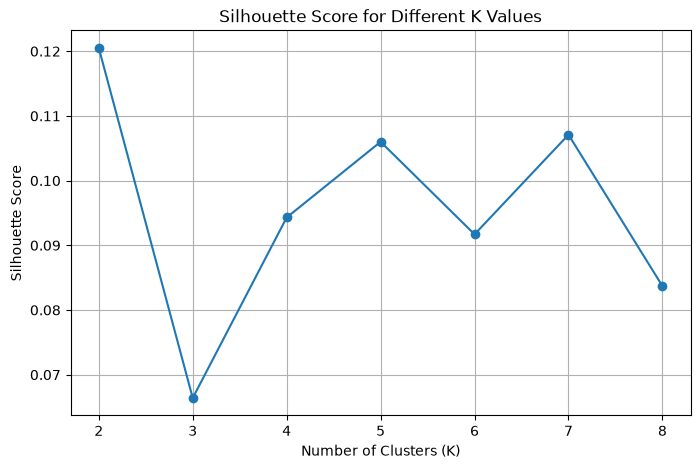

In [14]:
# ============================================================
# STEP 13 - FIND OPTIMAL NUMBER OF CLUSTERS
# ============================================================

from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. TAKE A REPRESENTATIVE SAMPLE
# ------------------------------------------------------------

sample_size = min(10000, X.shape[0])

rng = np.random.RandomState(42)

sample_indices = rng.choice(
    X.shape[0],
    size=sample_size,
    replace=False
)

X_sample = X[sample_indices]

print(f"Sample used for K selection: {X_sample.shape[0]:,} rows")


# ------------------------------------------------------------
# 2. TEST DIFFERENT VALUES OF K
# ------------------------------------------------------------

k_values = range(2, 9)

inertia_values = []
silhouette_values = []

for k in k_values:

    print(f"Testing K = {k}...")

    model = MiniBatchKMeans(
        n_clusters=k,
        random_state=42,
        batch_size=2048,
        n_init=3
    )

    labels = model.fit_predict(X_sample)

    inertia_values.append(model.inertia_)

    score = silhouette_score(
        X_sample,
        labels
    )

    silhouette_values.append(score)


# ------------------------------------------------------------
# 3. CREATE RESULTS TABLE
# ------------------------------------------------------------

k_results = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertia_values,
    "Silhouette Score": np.round(silhouette_values, 4)
})

display(k_results)


# ------------------------------------------------------------
# 4. SELECT K WITH HIGHEST SILHOUETTE SCORE
# ------------------------------------------------------------

best_k = k_results.loc[
    k_results["Silhouette Score"].idxmax(),
    "K"
]

best_score = k_results["Silhouette Score"].max()

print(f"✅ Optimal K based on silhouette score: {best_k}")
print(f"✅ Best silhouette score: {best_score:.4f}")


# ------------------------------------------------------------
# 5. PLOT SILHOUETTE SCORE
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    k_results["K"],
    k_results["Silhouette Score"],
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different K Values")
plt.xticks(list(k_values))
plt.grid(True)

plt.show()

In [15]:
# ============================================================
# STEP 14 - FINAL K-MEANS CLUSTERING
# ============================================================

from sklearn.cluster import MiniBatchKMeans

# Create final clustering model
kmeans = MiniBatchKMeans(
    n_clusters=int(best_k),
    random_state=42,
    batch_size=4096,
    n_init=5
)

# Train model and create cluster labels
cluster_labels = kmeans.fit_predict(X)

# Add cluster labels to the original SchemeMatch dataset
scheme_df["cluster"] = cluster_labels

# ------------------------------------------------------------
# RESULTS
# ------------------------------------------------------------

print("✅ K-Means clustering completed successfully!")
print("=" * 55)
print(f"Number of clusters : {best_k}")
print(f"Total records      : {len(scheme_df):,}")

print("\nCluster distribution:")

cluster_distribution = (
    scheme_df["cluster"]
    .value_counts()
    .sort_index()
    .to_frame("Number of Entrepreneurs")
)

cluster_distribution["Percentage"] = (
    cluster_distribution["Number of Entrepreneurs"]
    / len(scheme_df) * 100
).round(2)

display(cluster_distribution)

✅ K-Means clustering completed successfully!
Number of clusters : 2
Total records      : 523,775

Cluster distribution:


,Number of Entrepreneurs,Percentage
cluster,,
0,283083,54.05
1,240692,45.95


In [16]:
# ============================================================
# STEP 15 - CLUSTER PROFILING
# ============================================================

# Numerical features
numeric_features = [
    "economic_activities",
    "years_of_operation",
    "months_operated",
    "working_hours"
]

# Categorical features
categorical_features = [
    "mixed_activity",
    "major_activity_nic",
    "ownership_type",
    "education_level",
    "technical_training",
    "social_group",
    "bank_account",
    "establishment_location",
    "establishment_type",
    "nature_of_operation",
    "accounts_maintained",
    "computer_used",
    "internet_used",
    "operational_problem",
    "registered",
    "franchise"
]

# ------------------------------------------------------------
# NUMERICAL PROFILE
# ------------------------------------------------------------

numerical_profile = (
    scheme_df
    .groupby("cluster")[numeric_features]
    .mean()
    .round(2)
)

print("📊 Numerical Cluster Profile")
display(numerical_profile)


# ------------------------------------------------------------
# MOST COMMON CATEGORIES
# ------------------------------------------------------------

categorical_profile = {}

for col in categorical_features:

    categorical_profile[col] = (
        scheme_df
        .groupby("cluster")[col]
        .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else "Missing")
    )

categorical_profile = pd.DataFrame(categorical_profile)

print("\n📊 Most Common Category in Each Cluster")
display(categorical_profile)

📊 Numerical Cluster Profile


,economic_activities,years_of_operation,months_operated,working_hours
cluster,,,,
0,0.28,2.73,11.57,9.50
1,0.44,2.78,11.66,4.95



📊 Most Common Category in Each Cluster


,mixed_activity,major_activity_nic,ownership_type,education_level,technical_training,social_group,bank_account,establishment_location,establishment_type,nature_of_operation,accounts_maintained,computer_used,internet_used,operational_problem,registered,franchise
cluster,,,,,,,,,,,,,,,,
0,2,47,1,4,2,3,1,2,2,1,2,2,2,2,1,2
1,2,14,1,3,2,3,1,1,2,1,2,2,2,2,2,2


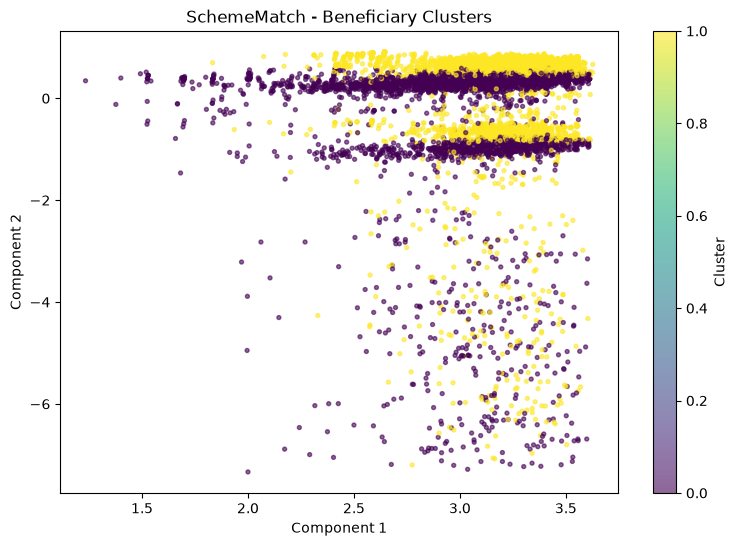

In [17]:
# ============================================================
# STEP 16 - VISUALIZE CLUSTERS USING PCA
# ============================================================

from sklearn.decomposition import TruncatedSVD
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. TAKE A SAMPLE FOR VISUALIZATION
# ------------------------------------------------------------

sample_size = min(10000, X.shape[0])

sample_indices = np.random.RandomState(42).choice(
    X.shape[0],
    size=sample_size,
    replace=False
)

X_sample = X[sample_indices]
labels_sample = scheme_df["cluster"].iloc[sample_indices]


# ------------------------------------------------------------
# 2. REDUCE HIGH-DIMENSIONAL DATA TO 2D
# ------------------------------------------------------------

svd = TruncatedSVD(
    n_components=2,
    random_state=42
)

X_2d = svd.fit_transform(X_sample)


# ------------------------------------------------------------
# 3. CREATE CLUSTER VISUALIZATION
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))

plt.scatter(
    X_2d[:, 0],
    X_2d[:, 1],
    c=labels_sample,
    s=8,
    alpha=0.6
)

plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.title("SchemeMatch - Beneficiary Clusters")

plt.colorbar(label="Cluster")

plt.show()

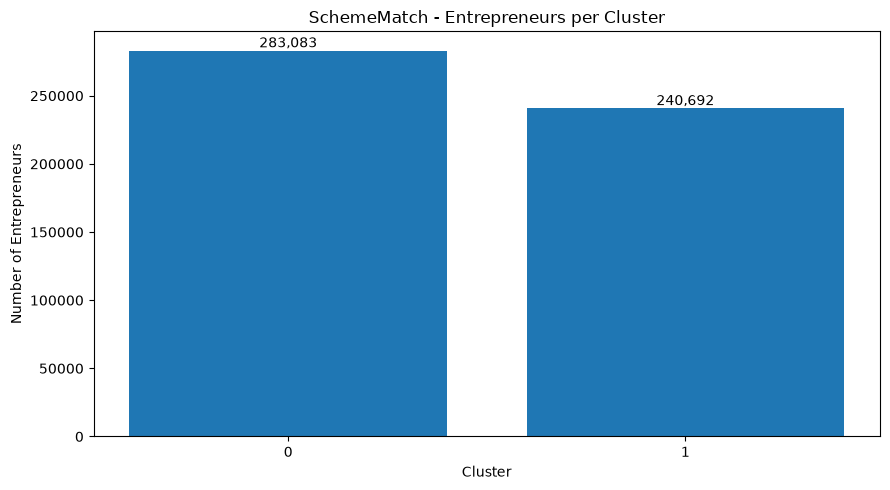

✅ Cluster size visualization completed!


In [18]:
# ============================================================
# STEP 17 - CLUSTER SIZE VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt

# Count entrepreneurs in each cluster
cluster_counts = (
    scheme_df["cluster"]
    .value_counts()
    .sort_index()
)

# Create bar chart
plt.figure(figsize=(9, 5))

bars = plt.bar(
    cluster_counts.index.astype(str),
    cluster_counts.values
)

plt.xlabel("Cluster")
plt.ylabel("Number of Entrepreneurs")
plt.title("SchemeMatch - Entrepreneurs per Cluster")

# Add values above bars
for bar, value in zip(bars, cluster_counts.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

print("✅ Cluster size visualization completed!")

In [19]:
# ============================================================
# STEP 18 - FINAL CLUSTER SUMMARY
# ============================================================

cluster_summary = (
    scheme_df
    .groupby("cluster")
    .agg(
        Entrepreneurs=("cluster", "size"),
        Avg_Years_Operation=("years_of_operation", "mean"),
        Avg_Months_Operated=("months_operated", "mean"),
        Avg_Working_Hours=("working_hours", "mean"),
        Avg_Economic_Activities=("economic_activities", "mean")
    )
    .round(2)
)

# Add percentage of total entrepreneurs
cluster_summary["Percentage"] = (
    cluster_summary["Entrepreneurs"]
    / len(scheme_df) * 100
).round(2)

display(cluster_summary)

print("✅ Final cluster summary created!")

,Entrepreneurs,Avg_Years_Operation,Avg_Months_Operated,Avg_Working_Hours,Avg_Economic_Activities,Percentage
cluster,,,,,,
0,283083,2.73,11.57,9.50,0.28,54.05
1,240692,2.78,11.66,4.95,0.44,45.95


✅ Final cluster summary created!


In [20]:
# ============================================================
# STEP 19 - IDENTIFY CLUSTER CHARACTERISTICS
# ============================================================

important_categorical_features = [
    "ownership_type",
    "education_level",
    "technical_training",
    "social_group",
    "bank_account",
    "establishment_location",
    "establishment_type",
    "nature_of_operation",
    "accounts_maintained",
    "computer_used",
    "internet_used",
    "operational_problem",
    "registered",
    "franchise"
]

cluster_characteristics = []

for cluster_id in sorted(scheme_df["cluster"].unique()):

    cluster_data = scheme_df[
        scheme_df["cluster"] == cluster_id
    ]

    row = {
        "Cluster": cluster_id,
        "Entrepreneurs": len(cluster_data)
    }

    for col in important_categorical_features:

        mode_values = cluster_data[col].mode()

        if len(mode_values) > 0:
            row[col] = mode_values.iloc[0]
        else:
            row[col] = "Unknown"

    cluster_characteristics.append(row)


cluster_characteristics = pd.DataFrame(
    cluster_characteristics
)

display(cluster_characteristics)

print("✅ Cluster characteristics identified successfully!")

,Cluster,Entrepreneurs,ownership_type,education_level,technical_training,social_group,bank_account,establishment_location,establishment_type,nature_of_operation,accounts_maintained,computer_used,internet_used,operational_problem,registered,franchise
0,0,283083,1,4,2,3,1,2,2,1,2,2,2,2,1,2
1,1,240692,1,3,2,3,1,1,2,1,2,2,2,2,2,2


✅ Cluster characteristics identified successfully!


In [21]:
# ============================================================
# STEP 20 - CREATE CLUSTER PROFILES
# ============================================================

cluster_profiles = (
    scheme_df
    .groupby("cluster")
    .agg(
        Entrepreneurs=("cluster", "size"),
        Avg_Years_Operation=("years_of_operation", "mean"),
        Avg_Months_Operated=("months_operated", "mean"),
        Avg_Working_Hours=("working_hours", "mean"),
        Avg_Economic_Activities=("economic_activities", "mean"),

        Common_Ownership=("ownership_type",
                          lambda x: x.mode().iloc[0]),

        Common_Education=("education_level",
                          lambda x: x.mode().iloc[0]),

        Common_Training=("technical_training",
                         lambda x: x.mode().iloc[0]),

        Common_Location=("establishment_location",
                         lambda x: x.mode().iloc[0]),

        Common_Establishment_Type=("establishment_type",
                                   lambda x: x.mode().iloc[0]),

        Common_Internet_Use=("internet_used",
                             lambda x: x.mode().iloc[0]),

        Common_Registration=("registered",
                             lambda x: x.mode().iloc[0])
    )
    .round(2)
)

# Calculate percentage
cluster_profiles["Percentage"] = (
    cluster_profiles["Entrepreneurs"]
    / len(scheme_df) * 100
).round(2)

display(cluster_profiles)

print("✅ Cluster profiles created successfully!")

,Entrepreneurs,Avg_Years_Operation,Avg_Months_Operated,Avg_Working_Hours,Avg_Economic_Activities,Common_Ownership,Common_Education,Common_Training,Common_Location,Common_Establishment_Type,Common_Internet_Use,Common_Registration,Percentage
cluster,,,,,,,,,,,,,
0,283083,2.73,11.57,9.50,0.28,1,4,2,2,2,2,1,54.05
1,240692,2.78,11.66,4.95,0.44,1,3,2,1,2,2,2,45.95


✅ Cluster profiles created successfully!


In [22]:
# ============================================================
# STEP 21 - CREATE SCHEME DATABASE
# ============================================================

scheme_data = [
    {
        "scheme": "PMEGP",
        "target": "New Micro Enterprises",
        "business_stage": "New",
        "focus": "Enterprise Creation",
        "training_required": "No"
    },
    {
        "scheme": "CGTMSE",
        "target": "Micro and Small Enterprises",
        "business_stage": "Existing/New",
        "focus": "Credit Support",
        "training_required": "No"
    },
    {
        "scheme": "MUDRA",
        "target": "Micro Enterprises",
        "business_stage": "Existing/New",
        "focus": "Business Loan",
        "training_required": "No"
    },
    {
        "scheme": "Stand-Up India",
        "target": "SC/ST and Women Entrepreneurs",
        "business_stage": "New",
        "focus": "Business Finance",
        "training_required": "No"
    }
]

scheme_database = pd.DataFrame(scheme_data)

display(scheme_database)

print("✅ Scheme database created successfully!")

,scheme,target,business_stage,focus,training_required
0,PMEGP,New Micro Enterprises,New,Enterprise Creation,No
1,CGTMSE,Micro and Small Enterprises,Existing/New,Credit Support,No
2,MUDRA,Micro Enterprises,Existing/New,Business Loan,No
3,Stand-Up India,SC/ST and Women Entrepreneurs,New,Business Finance,No


✅ Scheme database created successfully!


In [23]:
# ============================================================
# STEP 22 - SCHEME MATCHING FUNCTION
# ============================================================

def match_schemes(entrepreneur):
    """
    Match an entrepreneur with potentially relevant schemes.
    This is a prototype recommendation layer,
    not a final legal eligibility checker.
    """

    matches = []

    # --------------------------------------------------------
    # PMEGP
    # --------------------------------------------------------
    if entrepreneur["years_of_operation"] == 0:
        matches.append("PMEGP")

    # --------------------------------------------------------
    # CGTMSE
    # --------------------------------------------------------
    if entrepreneur["establishment_type"] in [1, 2]:
        matches.append("CGTMSE")

    # --------------------------------------------------------
    # MUDRA
    # --------------------------------------------------------
    if entrepreneur["establishment_type"] in [1, 2]:
        matches.append("MUDRA")

    # --------------------------------------------------------
    # Stand-Up India
    # --------------------------------------------------------
    if entrepreneur["social_group"] in [1, 2]:
        matches.append("Stand-Up India")

    return matches


print("✅ Scheme matching function created successfully!")

✅ Scheme matching function created successfully!


In [24]:
# ============================================================
# STEP 23 - TEST SCHEME MATCHING
# ============================================================

# Select one real entrepreneur from the dataset
entrepreneur = scheme_df.iloc[0]

# Apply scheme matching
matched_schemes = match_schemes(entrepreneur)

print("👤 ENTREPRENEUR PROFILE")
print("=" * 50)

display(
    entrepreneur.to_frame(name="Value")
)

print("\n🎯 POTENTIALLY MATCHED SCHEMES")
print("=" * 50)

if matched_schemes:
    for scheme in matched_schemes:
        print(f"✅ {scheme}")
else:
    print("No schemes matched by the prototype rules.")

print("\n⚠️ Note: Matching is a prototype and does not confirm legal eligibility.")

👤 ENTREPRENEUR PROFILE


,Value
mixed_activity,2
major_activity_nic,10
ownership_type,1
education_level,4
technical_training,2
social_group,1
economic_activities,0.0
bank_account,1
establishment_location,2
establishment_type,1



🎯 POTENTIALLY MATCHED SCHEMES
No schemes matched by the prototype rules.

⚠️ Note: Matching is a prototype and does not confirm legal eligibility.


In [25]:
# ============================================================
# STEP 24 - GENERATE SCHEMEMATCH RESULTS
# ============================================================

# Take 20 real entrepreneurs from the dataset
test_data = scheme_df.head(20).copy()

# Generate matched schemes for each entrepreneur
test_data["matched_schemes"] = test_data.apply(
    lambda row: ", ".join(match_schemes(row))
    if match_schemes(row)
    else "No Match",
    axis=1
)

# Select important columns for the final result
result_columns = [
    "cluster",
    "years_of_operation",
    "education_level",
    "technical_training",
    "social_group",
    "establishment_type",
    "internet_used",
    "registered",
    "matched_schemes"
]

scheme_match_results = test_data[result_columns]

display(scheme_match_results)

print("✅ SchemeMatch results generated successfully!")
print(f"Entrepreneurs tested: {len(scheme_match_results)}")

,cluster,years_of_operation,education_level,technical_training,social_group,establishment_type,internet_used,registered,matched_schemes
0,0,3,4,2,1,1,2,1,No Match
1,0,2,4,2,1,1,2,2,No Match
2,0,2,5,2,1,1,2,1,No Match
3,0,3,4,2,1,1,2,1,No Match
4,0,3,4,2,1,1,2,2,No Match
5,0,3,3,2,1,2,2,1,No Match
6,0,3,4,2,1,2,2,1,No Match
7,1,2,5,2,1,2,2,2,No Match
8,0,3,4,2,1,2,2,2,No Match
9,1,3,3,2,1,2,2,2,No Match


✅ SchemeMatch results generated successfully!
Entrepreneurs tested: 20


In [26]:
# ============================================================
# STEP 25 - EXPORT FINAL SCHEMEMATCH RESULTS
# ============================================================

# Save complete clustered dataset
scheme_df.to_csv(
    "SchemeMatch_Clustered_Data.csv",
    index=False
)

# Save the smaller SchemeMatch test results
scheme_match_results.to_csv(
    "SchemeMatch_Results.csv",
    index=False
)

# Save cluster profiles
cluster_profiles.to_csv(
    "SchemeMatch_Cluster_Profiles.csv"
)

print("✅ All SchemeMatch files exported successfully!")
print("=" * 55)
print("1. SchemeMatch_Clustered_Data.csv")
print("2. SchemeMatch_Results.csv")
print("3. SchemeMatch_Cluster_Profiles.csv")

✅ All SchemeMatch files exported successfully!
1. SchemeMatch_Clustered_Data.csv
2. SchemeMatch_Results.csv
3. SchemeMatch_Cluster_Profiles.csv


In [27]:
# ============================================================
# STEP 26 - SAVE SCHEMEINTEL ML MODEL
# ============================================================

import joblib

# Save the preprocessing pipeline
joblib.dump(
    preprocessor,
    "SchemeIntel_Preprocessor.pkl"
)

# Save the trained K-Means model
joblib.dump(
    kmeans,
    "SchemeIntel_KMeans_Model.pkl"
)

print("✅ SchemeIntel model saved successfully!")
print("=" * 55)
print("📁 SchemeIntel_Preprocessor.pkl")
print("📁 SchemeIntel_KMeans_Model.pkl")

✅ SchemeIntel model saved successfully!
📁 SchemeIntel_Preprocessor.pkl
📁 SchemeIntel_KMeans_Model.pkl


In [28]:
# ============================================================
# STEP 27 - VERIFY SAVED MODEL FILES
# ============================================================

import os

files_to_check = [
    "SchemeIntel_Preprocessor.pkl",
    "SchemeIntel_KMeans_Model.pkl"
]

for file in files_to_check:
    if os.path.exists(file):
        print(f"✅ {file} found")
    else:
        print(f"❌ {file} NOT found")

✅ SchemeIntel_Preprocessor.pkl found
✅ SchemeIntel_KMeans_Model.pkl found
